# Transmissionsspektroskopie und Atmosphären von Exoplaneten

Das Notebook lädt das JWST-Transmissionsspektrum des warmen Gasriesen HATS-6 b (NIRSpec PRISM, 0.6–5.3 µm) aus dem NASA Exoplanet Archive. Es prüft, ob die beiden beobachteten Transits übereinstimmen und ob das Spektrum von einer flachen Linie abweicht, rechnet die Banden von H₂O, CH₄, NH₃, CO₂ und CO in atmosphärische Skalenhöhen um und bestimmt aus Gleichgewichtstemperatur und veröffentlichter Atmosphärentemperatur die nötige Bond-Albedo.

Wie liest man aus der wellenlängenabhängigen Transittiefe eines Planeten ab, welche Moleküle seine Atmosphäre enthält und wie warm sie ist?

#### **Hintergrund**

Während eines Transits fällt ein kleiner Teil des Sternlichts durch die Atmosphäre am Rand des Planeten. Bei Wellenlängen, bei denen ein Molekül absorbiert, ist die Atmosphäre schon in großer Höhe undurchsichtig. Der Planet erscheint dort größer, und der Transit ist tiefer: Die Transittiefe $\delta(\lambda) = (R_p(\lambda)/R_\star)^2$ hängt von der Wellenlänge ab. Dieses **Transmissionsspektrum** zeigt die Absorptionsbanden der Moleküle.

Das **James Webb Space Telescope** misst mit NIRSpec PRISM den Bereich von etwa 0.6 bis 5.3 µm in einer einzigen Beobachtung. Dort liegen starke Banden der wichtigsten Moleküle:
- **Wasser (H₂O):** 1.4, 1.9, 2.7 µm
- **Methan (CH₄):** 2.3, 3.3 µm
- **Ammoniak (NH₃):** 3.0 µm
- **Kohlendioxid (CO₂):** 4.3 µm
- **Kohlenmonoxid (CO):** 4.7 µm

Wie hoch eine Bande über dem übrigen Spektrum liegt, hängt von der **Skalenhöhe** $H$ der Atmosphäre ab: Sie ist groß für heiße, leichte Atmosphären auf Planeten mit schwacher Schwerkraft.

#### **Herleitung**

**1. Skalenhöhe.** Im hydrostatischen Gleichgewicht gilt $dP/dz = -\rho g$, und für ein ideales Gas $P = \rho k_B T / (\mu m_H)$. Zusammen folgt $dP/dz = -P/H$, also fällt der Druck bei konstanter Temperatur exponentiell mit der Höhe:
$$P(z) = P_0\, e^{-z/H}, \qquad H = \frac{k_B T}{\mu m_H g} .$$
Dabei ist $\mu$ das mittlere Molekulargewicht in atomaren Masseneinheiten ($\mu \approx 2.3$ für eine Atmosphäre aus Wasserstoff und Helium), $m_H = 1.674\cdot10^{-24}$ g die Masse eines Wasserstoffatoms und $g = GM_p/R_p^2$ die Schwerebeschleunigung.

**2. Änderung der Transittiefe pro Skalenhöhe.** Liegt die Höhe, in der die Atmosphäre undurchsichtig wird, bei einer Wellenlänge um $H$ höher, wächst die verdeckende Fläche um einen Ring der Fläche $2\pi R_p H$. Bezogen auf die Sternfläche $\pi R_\star^2$ wächst die Transittiefe um
$$\Delta\delta = \frac{2 R_p H}{R_\star^2} .$$
Starke Banden in einer klaren Atmosphäre reichen über einige Skalenhöhen; Wolken oder Dunst in großer Höhe verdecken die tieferen Schichten und dämpfen die Banden auf eine Skalenhöhe oder weniger.

**3. Gleichgewichtstemperatur.** Der Planet nimmt die Strahlung des Sterns auf seinem Querschnitt $\pi R_p^2$ auf und strahlt sie über seine Oberfläche wieder ab. Der Stern liefert im Abstand $a$ den Fluss $\sigma T_\star^4 (R_\star/a)^2$. Bei voller Verteilung der Wärme über die ganze Kugel und der Bond-Albedo $A_B$ gilt
$$\pi R_p^2\,(1 - A_B)\,\sigma T_\star^4 \left(\frac{R_\star}{a}\right)^2 = 4\pi R_p^2\,\sigma T_\text{eq}^4 \quad\Rightarrow\quad T_\text{eq} = T_\star\sqrt{\frac{R_\star}{2a}}\,(1 - A_B)^{1/4} .$$
Mit $A_B = 0$ erhält man die höchste Gleichgewichtstemperatur $T_{\text{eq},0}$.

**4. Bond-Albedo aus der Temperatur.** Liegt die aus dem Spektrum bestimmte Temperatur $T$ deutlich unter $T_{\text{eq},0}$, muss der Planet einen Teil des Lichts zurückwerfen. Aus Punkt 3 folgt
$$A_B = 1 - \left(\frac{T}{T_{\text{eq},0}}\right)^4 .$$
Eine hohe Albedo ($A_B > 0.5$) weist auf helle Wolken oder Dunst hin. Die Rechnung nimmt an, dass $T$ die Temperatur ist, mit der der Planet seine Energie abstrahlt; ein Spektrum misst aber nur die Schichten am Rand in einer bestimmten Höhe.

**5. Ist das Spektrum flach?** Ohne Atmosphäre oder unter einer dichten, grauen Wolkendecke wäre die Transittiefe bei allen Wellenlängen gleich. Die gewichtete mittlere Tiefe $\bar\delta = \sum_i w_i\delta_i / \sum_i w_i$ mit $w_i = 1/\sigma_i^2$ ist dann das beste Modell, und
$$\chi^2 = \sum_i \frac{(\delta_i - \bar\delta)^2}{\sigma_i^2}$$
folgt einer $\chi^2$-Verteilung mit $N - 1$ Freiheitsgraden. Ein viel größeres $\chi^2$ heißt: Das Spektrum hat Strukturen, die über das Rauschen hinausgehen.

#### **Daten**

Ziel ist **HATS-6 b**: ein warmer Gasriese mit etwa einer Saturnmasse und einem Jupiterradius, der einen M-Zwerg alle 3.3 Tage umkreist. Weil der Stern klein ist, sind die Signale der Atmosphäre groß. Das Spektrum stammt aus zwei Transits, beobachtet mit JWST NIRSpec PRISM (Guzmán Caloca et al. 2026). Das NASA Exoplanet Archive führt die Spektren in der Tabelle `spectra`: beide Transits einzeln (470 Punkte) und ihr gemeinsames Spektrum (120 Punkte).

Die Spektrendateien liefert das Archiv aus einem Arbeitsbereich seiner Weboberfläche; das ist keine dokumentierte Schnittstelle und kann sich ändern. Andere Planeten mit JWST-Spektren gehen ebenso, zum Beispiel `SPEC_PLANET = "WASP-39 b"` mit der CO₂-Bande bei 4.3 µm.

In [2]:
# In Colab fehlt astroquery; lokal ist es meist schon installiert
import importlib.util, subprocess, sys
if importlib.util.find_spec("astroquery") is None:
    if "google.colab" not in sys.modules:       # lokal nichts automatisch installieren: pip würde numpy mit aktualisieren
        raise ImportError("Es fehlt astroquery; bitte lokal selbst installieren, am besten mit conda (conda-forge), "
                          "damit numpy und die übrigen Pakete unverändert bleiben")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "astroquery"], check=True)

In [3]:
import os
from pathlib import Path

# Downloads landen im Ordner "astrodata" neben dem Notebook statt in den Caches im Home-Verzeichnis.
# Das muss vor dem ersten Import von astropy passieren; sonst den Kernel neu starten.
ASTRODATA = Path.cwd() / "astrodata"
for sub in ("astropy", "lightkurve"):
    (ASTRODATA / sub).mkdir(parents=True, exist_ok=True)
os.environ["XDG_CACHE_HOME"] = str(ASTRODATA)

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from astropy.io import ascii
from astroquery.ipac.nexsci.nasa_exoplanet_archive import NasaExoplanetArchive
from scipy.stats import chi2 as chi2_dist

SPEC_PLANET = "HATS-6 b"
T_RETRIEVED = 514     # K, Atmosphärentemperatur aus der Analyse von Guzmán Caloca et al. (2026); für andere Planeten None
MU = 2.3              # mittleres Molekulargewicht einer Wasserstoff-Helium-Atmosphäre [u]
G_CGS = 6.674e-8      # Gravitationskonstante [cm³ g⁻¹ s⁻²]

def download_spectrum(spec_path):
    """Lädt eine Spektrendatei aus dem NASA Exoplanet Archive (über den Arbeitsbereich der Weboberfläche)."""
    base = "https://exoplanetarchive.ipac.caltech.edu"
    page = requests.get(base + "/cgi-bin/atmospheres/nph-firefly?atmospheres", timeout=60).text
    workspace = re.search(r"/workspace/TMP_[A-Za-z0-9_]+", page).group(0)
    r = requests.get(f"{base}{workspace}/atmospheres/tab1/data/{spec_path}", timeout=60)
    r.raise_for_status()
    return ascii.read(r.text, format="ipac")

spec_meta = NasaExoplanetArchive.query_criteria(table="spectra", where=f"pl_name='{SPEC_PLANET}'").to_pandas()
spec_meta["authors"] = spec_meta["authors"].str.replace("&aacute;", "á")
print(f"{len(spec_meta)} Spektren von {SPEC_PLANET} im Archiv:")
display(spec_meta[["spec_type", "instrument", "minwavelng", "maxwavelng", "num_datapoints", "authors", "bibcode", "note"]])

pp = NasaExoplanetArchive.query_criteria(
    table="pscomppars", where=f"pl_name='{SPEC_PLANET}'",
    select="pl_name, pl_orbper, pl_rade, pl_radj, pl_bmasse, pl_bmassj, pl_eqt, st_rad, st_teff, st_spectype, pl_ratdor"
).to_pandas().iloc[0]
print(f"Planet: R = {pp['pl_radj']:.2f} R_Jup, M = {pp['pl_bmassj']:.2f} M_Jup, P = {pp['pl_orbper']:.2f} d, "
      f"T_eq (Katalog) = {pp['pl_eqt']:.0f} K")
print(f"Stern:  {pp['st_spectype']}, T = {pp['st_teff']:.0f} K, R = {pp['st_rad']:.2f} R_Sonne")

3 Spektren von HATS-6 b im Archiv:


,spec_type,instrument,minwavelng,maxwavelng,num_datapoints,authors,bibcode,note
0,Transmission,Near Infrared Spectrograph (NIRSpec) - PRISM,0.5492,5.6377,470,Guzmán Caloca et al. 2026,2026AJ....172..193G,Visit 1; Eureka1 pipeline; Figure 2
1,Transmission,Near Infrared Spectrograph (NIRSpec) - PRISM,0.5547,5.6489,470,Guzmán Caloca et al. 2026,2026AJ....172..193G,Visit 2; Eureka1 pipeline; Figure 2
2,Transmission,Near Infrared Spectrograph (NIRSpec) - PRISM,0.6200,5.3800,120,Guzmán Caloca et al. 2026,2026AJ....172..193G,Co-added spectrum; Eureka1 pipeline; Figure 2


Planet: R = 1.00 R_Jup, M = 0.32 M_Jup, P = 3.33 d, T_eq (Katalog) = 713 K
Stern:  M1 V, T = 3724 K, R = 0.57 R_Sonne


#### **Reduktion**

##### *1. Spektren laden und die beiden Transits vergleichen*

Stimmen die beiden Transits im Rahmen ihrer Fehler überein?

Die Zelle lädt alle JWST-Transmissionsspektren derselben Veröffentlichung und rechnet die Tiefen von Prozent in ppm um (1 % = 10 000 ppm). Einzelne Kanäle können durch Detektorfehler weit danebenliegen. Punkte, die mehr als 5σ von einem gleitenden Median über 7 Nachbarn abweichen, werden deshalb vor dem Vergleich entfernt und aufgelistet. Danach wird der zweite Transit auf das Wellenlängengitter des ersten interpoliert; die beiden Gitter sind leicht gegeneinander verschoben. Stimmen die Transits überein, ist die Differenz geteilt durch ihren Fehler normalverteilt mit Breite 1, und $\chi^2$ pro Freiheitsgrad liegt nahe 1.

  Visit 1: Kanal bei 1.584 µm entfernt (20596 ppm statt etwa 32784 ppm, 91σ)
  Visit 2: Kanal bei 1.617 µm entfernt (22966 ppm statt etwa 32750 ppm, 69σ)


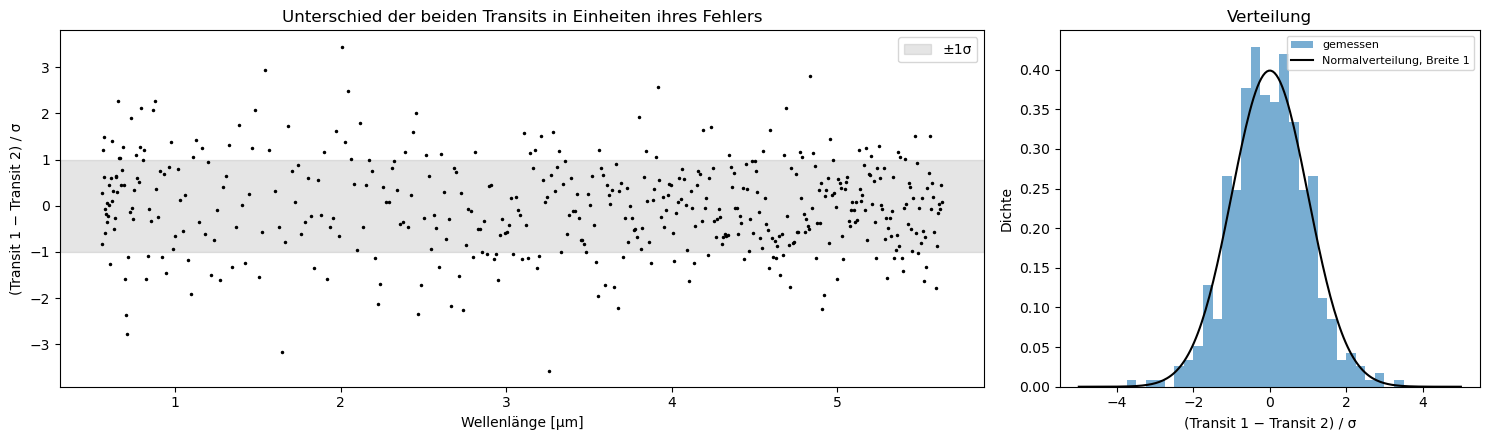

467 Wellenlängen: χ²/Freiheitsgrad = 0.97, mittlerer Versatz -23 ppm, Anteil |Unterschied| > 3σ: 0.6%
Hauptspektrum: Co-added spectrum; Eureka1 pipeline; Figure 2 (120 Punkte, 0.62–5.38 µm, mittlerer Fehler 133 ppm)


In [4]:
jwst = spec_meta[spec_meta["facility"].str.contains("JWST") & (spec_meta["spec_type"] == "Transmission")].copy()
jwst["coadded"] = jwst["note"].str.contains("Co-added", case=False, na=False)
main = jwst.sort_values(["coadded", "num_datapoints"], ascending=False).iloc[0]
spectra = {r["note"]: download_spectrum(r["spec_path"]) for _, r in jwst[jwst["bibcode"] == main["bibcode"]].iterrows()}

to_ppm = lambda s, col: np.array(s[col], dtype=float) * 1e4              # Prozent -> ppm
spec = spectra[main["note"]]
wl, dep, err = np.array(spec["CENTRALWAVELNG"], dtype=float), to_ppm(spec, "PL_TRANDEP"), to_ppm(spec, "PL_TRANDEPERR1")

def clean(s, name, nsig=5):
    """Wellenlänge, Tiefe, Fehler ohne Kanäle, die mehr als nsig·σ vom gleitenden Median abweichen."""
    w, d, e = np.array(s["CENTRALWAVELNG"], dtype=float), to_ppm(s, "PL_TRANDEP"), to_ppm(s, "PL_TRANDEPERR1")
    med = pd.Series(d).rolling(7, center=True, min_periods=3).median().to_numpy()
    bad = np.abs(d - med) > nsig * e
    for wi, di, mi, ei in zip(w[bad], d[bad], med[bad], e[bad]):
        print(f"  {name}: Kanal bei {wi:.3f} µm entfernt ({di:.0f} ppm statt etwa {mi:.0f} ppm, {abs(di - mi) / ei:.0f}σ)")
    return w[~bad], d[~bad], e[~bad]

visits = [n for n in spectra if n != main["note"]]
if len(visits) >= 2:
    wa, da, ea = clean(spectra[visits[0]], visits[0].split(";")[0])
    wb, db_, eb_ = clean(spectra[visits[1]], visits[1].split(";")[0])
    inside = (wa >= wb.min()) & (wa <= wb.max())
    wa, da, ea = wa[inside], da[inside], ea[inside]
    db, eb = np.interp(wa, wb, db_), np.interp(wa, wb, eb_)
    z = (da - db) / np.hypot(ea, eb)

    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})
    axes[0].plot(wa, z, ".", ms=3, c="black")
    axes[0].axhspan(-1, 1, color="grey", alpha=0.2, label="±1σ")
    axes[0].set_xlabel("Wellenlänge [µm]")
    axes[0].set_ylabel("(Transit 1 − Transit 2) / σ")
    axes[0].set_title("Unterschied der beiden Transits in Einheiten ihres Fehlers")
    axes[0].legend()
    xs = np.linspace(-5, 5, 200)
    axes[1].hist(z, bins=np.linspace(-5, 5, 41), density=True, color="tab:blue", alpha=0.6, label="gemessen")
    axes[1].plot(xs, np.exp(-xs ** 2 / 2) / np.sqrt(2 * np.pi), c="black", label="Normalverteilung, Breite 1")
    axes[1].set_xlabel("(Transit 1 − Transit 2) / σ")
    axes[1].set_ylabel("Dichte")
    axes[1].set_title("Verteilung")
    axes[1].legend(fontsize=8)
    fig.tight_layout()
    plt.show()
    print(f"{len(z)} Wellenlängen: χ²/Freiheitsgrad = {np.mean(z ** 2):.2f}, mittlerer Versatz {np.median(da - db):+.0f} ppm, "
          f"Anteil |Unterschied| > 3σ: {np.mean(np.abs(z) > 3):.1%}")
print(f"Hauptspektrum: {main['note']} ({len(wl)} Punkte, {wl.min():.2f}–{wl.max():.2f} µm, mittlerer Fehler {np.median(err):.0f} ppm)")

#### **Eigene Messung**

##### *2. Das Transmissionsspektrum*

Welche Banden zeigt das Spektrum zwischen 0.6 und 5.3 µm, und wie groß sind sie in Skalenhöhen?

Die rechte Achse rechnet die Tiefe in Skalenhöhen über dem Median um (Herleitung, Punkt 2), bei der Temperatur aus der veröffentlichten Analyse. Die farbigen Streifen markieren die ungefähren Bandenmitten. Eine Markierung ist kein Nachweis: Banden verschiedener Moleküle überlappen, und welche Moleküle wirklich beitragen, entscheidet erst ein Modell der ganzen Atmosphäre.

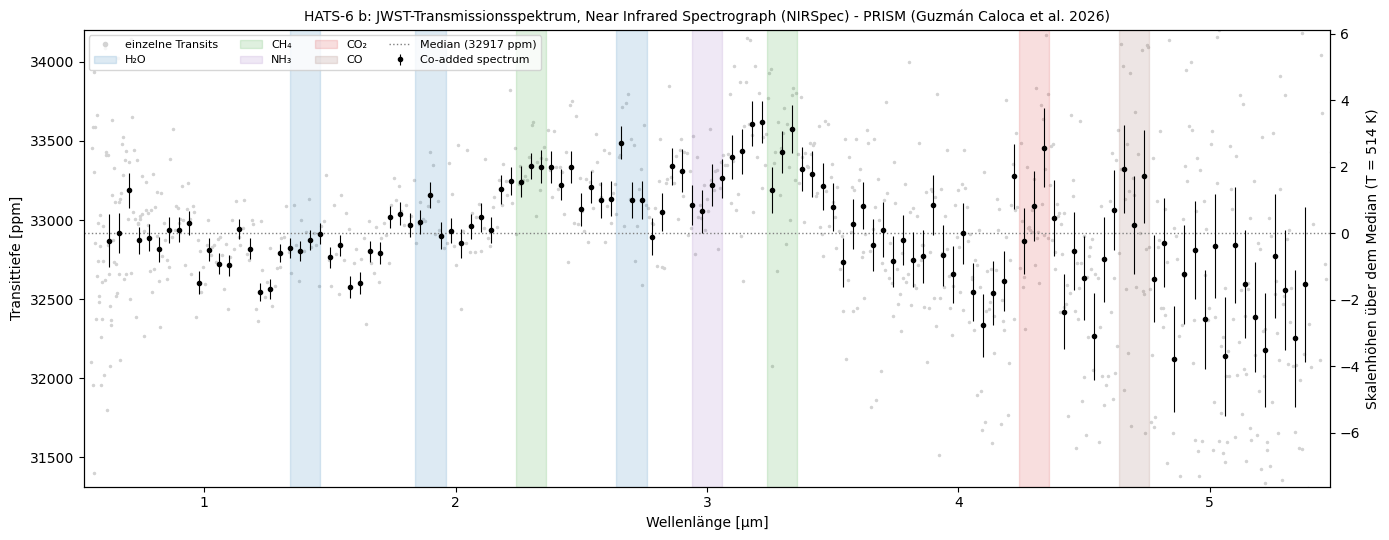

g = 8.0 m/s²
T = 713 K:  H = 321 km  ->  291 ppm pro Skalenhöhe
T = 514 K:  H = 232 km  ->  210 ppm pro Skalenhöhe


In [5]:
R_p, M_p, R_s = pp["pl_rade"] * 6.371e8, pp["pl_bmasse"] * 5.972e27, pp["st_rad"] * 6.957e10      # cgs
g = G_CGS * M_p / R_p ** 2
scale_height = lambda T: 1.381e-16 * T / (MU * 1.6735e-24 * g)              # H = kT / (μ m_H g)  [cm]
ppm_per_H = lambda T: 2 * R_p * scale_height(T) / R_s ** 2 * 1e6            # Änderung der Tiefe pro H  [ppm]
T_axis = T_RETRIEVED or pp["pl_eqt"]

BANDS = {"H₂O": [1.4, 1.9, 2.7], "CH₄": [2.3, 3.3], "NH₃": [3.0], "CO₂": [4.3], "CO": [4.7]}
COLORS = {"H₂O": "tab:blue", "CH₄": "tab:green", "NH₃": "tab:purple", "CO₂": "tab:red", "CO": "tab:brown"}
base = np.median(dep)

fig, ax = plt.subplots(figsize=(14, 5.5))
for note in visits:
    s = spectra[note]
    ax.plot(np.array(s["CENTRALWAVELNG"], dtype=float), to_ppm(s, "PL_TRANDEP"), ".", c="lightgrey", ms=3, zorder=1)
ax.plot([], [], ".", c="lightgrey", label="einzelne Transits")
ax.errorbar(wl, dep, err, fmt="o", c="black", ms=3, lw=0.8, label=main["note"].split(";")[0], zorder=3)
for mol, centres in BANDS.items():
    for i, c in enumerate(centres):
        if wl.min() < c < wl.max():
            ax.axvspan(c - 0.06, c + 0.06, color=COLORS[mol], alpha=0.15, label=mol if i == 0 else None)
ax.axhline(base, color="grey", ls=":", lw=1, label=f"Median ({base:.0f} ppm)")
pad = 0.3 * np.ptp(dep)
ax.set_ylim((dep - err).min() - pad, (dep + err).max() + pad)                # einzelne Transits streuen an den Rändern
ax.set_xlim(wl.min() - 0.1, wl.max() + 0.1)
ax.set_xlabel("Wellenlänge [µm]")
ax.set_ylabel("Transittiefe [ppm]")
ax.set_title(f"{SPEC_PLANET}: JWST-Transmissionsspektrum, {main['instrument']} ({main['authors']})", fontsize=10)
ax.legend(fontsize=8, ncol=4, loc="upper left")
ax_h = ax.twinx()
ax_h.set_ylim((np.array(ax.get_ylim()) - base) / ppm_per_H(T_axis))
ax_h.set_ylabel(f"Skalenhöhen über dem Median (T = {T_axis:.0f} K)")
fig.tight_layout()
plt.show()

print(f"g = {g / 100:.1f} m/s²")
for T in [pp["pl_eqt"], T_RETRIEVED]:
    if T:
        print(f"T = {T:.0f} K:  H = {scale_height(T) / 1e5:.0f} km  ->  {ppm_per_H(T):.0f} ppm pro Skalenhöhe")

##### *3. Höhe der Banden*

Wie weit ragt jede Bande über den Median hinaus?

Für jede Bandenmitte mittelt die Zelle die Punkte im Abstand von höchstens 0.1 µm und zieht den Median des Spektrums ab; pro Molekül zählt die stärkste Bande. Der Fehler ist der Fehler dieses Mittelwerts. Die Signifikanz ist nur ein grober Anhaltspunkt: Der Median ist kein echtes Kontinuum, und benachbarte Banden (H₂O bei 2.7 µm, NH₃ bei 3.0 µm, CH₄ bei 3.3 µm) überlappen.

In [6]:
rows = []
for mol, cs in BANDS.items():
    best = None
    for c in cs:
        sel = np.abs(wl - c) < 0.1
        if wl.min() < c < wl.max() and sel.any():
            ex, ex_err = dep[sel].mean() - base, np.sqrt(np.sum(err[sel] ** 2)) / sel.sum()
            if best is None or ex > best[1]:
                best = (c, ex, ex_err)
    if best:
        c, ex, ex_err = best
        rows.append((mol, c, ex, ex_err, ex / ppm_per_H(pp["pl_eqt"]), ex / ppm_per_H(T_axis)))
bands = pd.DataFrame(rows, columns=["Molekül", "Bande [µm]", "Überschuss [ppm]", "Fehler [ppm]",
                                    f"H bei {pp['pl_eqt']:.0f} K", f"H bei {T_axis:.0f} K"])
bands["Signifikanz [σ]"] = bands["Überschuss [ppm]"] / bands["Fehler [ppm]"]
display(bands.round(1))

,Molekül,Bande [µm],Überschuss [ppm],Fehler [ppm],H bei 713 K,H bei 514 K,Signifikanz [σ]
0,H₂O,2.7,237.2,50.5,0.8,1.1,4.7
1,CH₄,3.3,510.7,63.1,1.8,2.4,8.1
2,NH₃,3.0,241.2,64.6,0.8,1.1,3.7
3,CO₂,4.3,223.6,101.2,0.8,1.1,2.2
4,CO,4.7,134.9,126.5,0.5,0.6,1.1


#### **Modell und Fit**

##### *4. Flaches Spektrum gegen Atmosphäre, Temperatur und Albedo*

Ist das Spektrum mit einer flachen Linie verträglich, und welche Albedo braucht der Planet, damit seine Atmosphäre so kühl ist wie gemessen?

Zuerst der Test aus Herleitung, Punkt 5. Danach die Gleichgewichtstemperatur ohne Albedo (Punkt 3) und die Bond-Albedo, die zur Temperatur aus der veröffentlichten Analyse passt (Punkt 4).

Flaches Spektrum: mittlere Tiefe 32931 ppm, χ² = 631 bei 119 Freiheitsgraden (χ²/Freiheitsgrad = 5.3), Wahrscheinlichkeit p = 8.5e-71

Gleichgewichtstemperatur T_eq = T* √(R*/2a) = 3724 K · √(1/(2 · 13.65)) = 713 K   (Katalog 713 K)
Temperatur aus dem Spektrum (Guzmán Caloca et al. 2026): 514 K, 199 K kühler
Nötige Bond-Albedo A_B = 1 − (T/T_eq)⁴ = 0.73


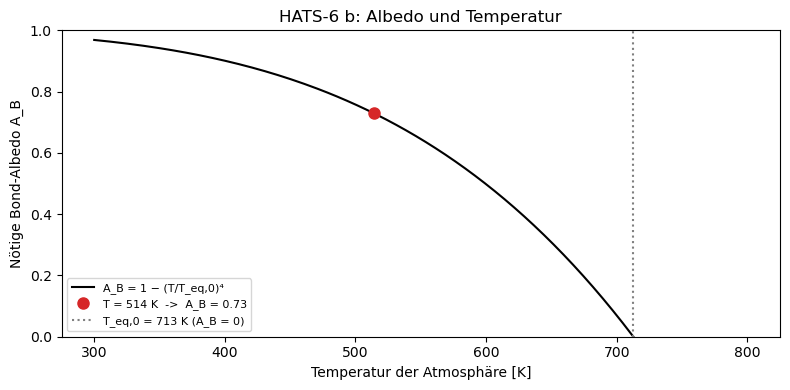

In [7]:
w = 1 / err ** 2
flat = np.sum(w * dep) / np.sum(w)
chi2_flat = np.sum(((dep - flat) / err) ** 2)
dof = len(dep) - 1
print(f"Flaches Spektrum: mittlere Tiefe {flat:.0f} ppm, χ² = {chi2_flat:.0f} bei {dof} Freiheitsgraden "
      f"(χ²/Freiheitsgrad = {chi2_flat / dof:.1f}), Wahrscheinlichkeit p = {chi2_dist.sf(chi2_flat, dof):.1e}")

T_eq0 = pp["st_teff"] * np.sqrt(1 / (2 * pp["pl_ratdor"]))                    # A_B = 0, volle Wärmeverteilung
print(f"\nGleichgewichtstemperatur T_eq = T* √(R*/2a) = {pp['st_teff']:.0f} K · √(1/(2 · {pp['pl_ratdor']:.2f})) "
      f"= {T_eq0:.0f} K   (Katalog {pp['pl_eqt']:.0f} K)")
if T_RETRIEVED:
    A_B = 1 - (T_RETRIEVED / T_eq0) ** 4
    print(f"Temperatur aus dem Spektrum (Guzmán Caloca et al. 2026): {T_RETRIEVED} K, {T_eq0 - T_RETRIEVED:.0f} K kühler")
    print(f"Nötige Bond-Albedo A_B = 1 − (T/T_eq)⁴ = {A_B:.2f}")

T = np.linspace(300, 800, 200)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(T, 1 - (T / T_eq0) ** 4, c="black", label="A_B = 1 − (T/T_eq,0)⁴")
if T_RETRIEVED:
    ax.plot([T_RETRIEVED], [A_B], "o", c="tab:red", ms=8, label=f"T = {T_RETRIEVED} K  ->  A_B = {A_B:.2f}")
ax.axvline(T_eq0, color="grey", ls=":", label=f"T_eq,0 = {T_eq0:.0f} K (A_B = 0)")
ax.set_xlabel("Temperatur der Atmosphäre [K]")
ax.set_ylabel("Nötige Bond-Albedo A_B")
ax.set_title(f"{SPEC_PLANET}: Albedo und Temperatur")
ax.set_ylim(0, 1)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

#### **Eigene Messung gegen den Katalog**

##### *5. Vergleich mit der Veröffentlichung*

Passen die eigenen Zahlen zu den Ergebnissen von Guzmán Caloca et al. (2026)?

Die Veröffentlichung bestimmt die Atmosphäre mit einem vollständigen Modell (Retrieval) und findet H₂O, CH₄, CO₂ und NH₃, eine Temperatur von etwa 514 K, rund 200 K unter der Gleichgewichtstemperatur von 713 K, und erklärt den Unterschied mit einer hohen Bond-Albedo von etwa 0.71 durch reflektierende Wolken oder Dunst.

In [8]:
strongest = bands.sort_values("Überschuss [ppm]", ascending=False)["Molekül"].tolist()
print(f"{'Größe':<38}{'eigene Rechnung':<28}{'Katalog / Veröffentlichung'}")
print("-" * 98)
print(f"{'Gleichgewichtstemperatur (A_B = 0)':<38}{f'{T_eq0:.0f} K':<28}{pp['pl_eqt']:.0f} K (Katalog)")
if T_RETRIEVED:
    print(f"{'Bond-Albedo für 514 K':<38}{f'{A_B:.2f}':<28}≈ 0.71 (Veröffentlichung)")
print(f"{'Spektrum flach?':<38}{f'nein, χ²/Fg = {chi2_flat / dof:.1f}':<28}nein: Moleküle nachgewiesen")
print(f"{'Banden nach Höhe':<38}{', '.join(strongest):<28}H₂O, CH₄, CO₂, NH₃ (Retrieval)")
print(f"\nQuelle: {main['authors']}, {main['bibcode']}")

Größe                                 eigene Rechnung             Katalog / Veröffentlichung
--------------------------------------------------------------------------------------------------
Gleichgewichtstemperatur (A_B = 0)    713 K                       713 K (Katalog)
Bond-Albedo für 514 K                 0.73                        ≈ 0.71 (Veröffentlichung)
Spektrum flach?                       nein, χ²/Fg = 5.3           nein: Moleküle nachgewiesen
Banden nach Höhe                      CH₄, NH₃, H₂O, CO₂, CO      H₂O, CH₄, CO₂, NH₃ (Retrieval)

Quelle: Guzmán Caloca et al. 2026, 2026AJ....172..193G


Ergebnis beim Lauf vom 2026-10-12:

- **Planet und Stern:** $R_p = 1.00\,R_J$, $M_p = 0.32\,M_J$, $P = 3.33$ d um einen M1-Zwerg mit $0.57\,R_\odot$. Daraus folgen $g = 8.0$ m/s² und $H = 321$ km bei 713 K, also 291 ppm pro Skalenhöhe (210 ppm bei 514 K). Der Wert ist groß, weil der Stern klein ist: $\Delta\delta \propto 1/R_\star^2$.
- **Die beiden Transits:** Jedes der veröffentlichten Einzelspektren hat bei 1.6 µm einen Kanal, der um 70 bis 90σ danebenliegt. Ohne diese beiden Kanäle stimmen die Transits überein: $\chi^2$ pro Freiheitsgrad 0.97, Versatz −23 ppm bei Fehlern von etwa 130 ppm pro Kanal.
- **Flaches Spektrum:** ausgeschlossen, $\chi^2 = 631$ bei 119 Freiheitsgraden ($p \approx 10^{-70}$). Das Spektrum hat echte Strukturen.
- **Banden:** CH₄ bei 3.3 µm ist mit +511 ± 63 ppm (2.4 Skalenhöhen bei 514 K) am deutlichsten. H₂O bei 2.7 µm (+237 ± 51 ppm) und NH₃ bei 3.0 µm (+241 ± 65 ppm) liegen im selben breiten Buckel zwischen 2.2 und 3.6 µm und lassen sich mit dieser einfachen Auswertung nicht trennen. CO₂ bei 4.3 µm (+224 ± 101 ppm, 2σ) ist schwach, CO zeigt nichts. Die Veröffentlichung weist alle vier Moleküle H₂O, CH₄, CO₂ und NH₃ mit einem vollständigen Modell nach.
- **Temperatur und Albedo:** $T_\text{eq} = 713$ K wie im Katalog. Für die veröffentlichte Temperatur von 514 K braucht der Planet eine Bond-Albedo von 0.73; die Veröffentlichung gibt etwa 0.71 an.

#### **Variationen**

Jeweils zuerst die Vorhersage notieren, dann den Code ändern und prüfen:

1. **Schwere Atmosphäre:** Setze das mittlere Molekulargewicht $\mu$ von 2.3 auf 18 (Wasserdampf) oder 44 (CO₂). Um welchen Faktor schrumpfen Skalenhöhe und Bandenhöhen in ppm, und wie viele Skalenhöhen hätte dann die CH₄-Bande? *(Vorhersage: um den Faktor 8 bzw. 19; die gemessenen Banden wären dann mehr als 10 Skalenhöhen hoch, was eine Wasserstoff-Atmosphäre nahelegt.)*
2. **Keine Wärmeverteilung:** Strahlt jede Stelle der Tagseite ihre Energie sofort wieder ab, ist die mittlere Tagseitentemperatur $T_\star\sqrt{R_\star/a}\,(2/3)^{1/4}$ statt $T_\star\sqrt{R_\star/2a}$ (Cowan & Agol 2011). Wie viel wärmer ist das, und welche Albedo bräuchte man dann für 514 K?
3. **Wolkendecke:** Ersetze alle Tiefen über $\bar\delta + 1\,H$ durch diesen Wert, als ob eine Wolkendecke die tieferen Schichten verdeckt. Wie ändern sich $\chi^2$ des flachen Modells und die Bandenhöhen?
4. **Anderer Planet:** Setze `SPEC_PLANET = "WASP-39 b"` und `T_RETRIEVED = None`. Wo liegt die stärkste Bande?

#### **Nächste Schritte**

So geht die Analyse einer Atmosphäre in der Forschung weiter:
- **Retrieval:** Ein Modell des Strahlungstransports (zum Beispiel `petitRADTRANS` oder `TauREx`) wird mit Nested Sampling an das Spektrum angepasst. Es liefert die Häufigkeiten der Moleküle, das Verhältnis von Kohlenstoff zu Sauerstoff, die Temperatur und die Höhe der Wolken mit Unsicherheiten.
- **Sternflecken:** Bei M-Zwergen können Flecken und helle Regionen auf dem Stern das Transmissionsspektrum verfälschen; ein Retrieval muss sie mitmodellieren.
- **Emissionsspektren:** In der sekundären Bedeckung sieht man das Licht der Tagseite selbst und daraus, wie die Temperatur mit der Höhe verläuft. Das NASA Exoplanet Archive führt solche Spektren in derselben Tabelle mit `spec_type = 'Eclipse'`.
- **Phasenkurven:** Eine Beobachtung über einen ganzen Umlauf zeigt den Unterschied zwischen Tag- und Nachtseite und damit, wie gut Winde die Wärme verteilen.

#### **Referenzen**

- Guzmán Caloca et al. (2026), AJ 172, 193 (bibcode 2026AJ....172..193G): JWST NIRSpec PRISM Transmissionsspektrum von HATS-6 b.
- Seager, S. & Sasselov, D. D. (2000): *Theoretical Transmission Spectra during Extrasolar Giant Planet Transits*, ApJ 537, 916.
- Cowan, N. B. & Agol, E. (2011): *The Statistics of Albedo and Heat Recirculation on Hot Exoplanets*, ApJ 729, 54.
- Kreidberg, L. (2018): *Exoplanet Atmosphere Measurements from Transmission Spectroscopy and Other Planet Star Combined Light Observations*, in *Handbook of Exoplanets*, Springer.
- Madhusudhan, N. (2019): *Exoplanetary Atmospheres: Key Insights, Challenges, and Prospects*, ARA&A 57, 617.